In [122]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
from sklearn.metrics import r2_score
import pickle

from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot
from statistics_functions import chi_squared
from cluster_error_prop import T500_from_L500

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
u.Gyr.to(u.s)

3.15576e+16

In [6]:
with open('data/equilibrium_clusters.pkl', 'rb') as file:
    # Load the data into nfws_subset variable
    nfws_subset = pickle.load(file)

In [7]:
test_nfw = nfws_subset[0]

In [8]:
test_nfw

In [86]:
u.GeV.to(u.erg)

0.0016021766339999997

In [41]:
G_conv = (const.G/const.c**2).to(u.Mpc/u.Msun)

In [126]:
def E_tot(nfw, L=None): # remove ".value" once ive gotten units figured out
    pe = G_conv * (nfw.M500.value)**2*u.Msun**2/(nfw.R500.value*u.Mpc)
    
    if not L:
        L = nfw.L500.value
    xmin = 0.001
    xmax = 1
    xs = np.logspace(np.log10(xmin), np.log10(xmax), num=50)
    rs = xs*nfw.R500
    
    
    Tbs = np.array([T.value for T in np.asarray(nfw.T_g(rs, match_gaspari=True))]) # in GeV
    Tbs_norm = Tbs/Tbs[-1] # unitless
    Tbs_Ldep = Tbs_norm * T500_from_L500(np.log10(L))
    nbs = [n.value for n in np.asarray(nfw.n_e(rs))] # in 1/Mpc^3
    ke_b = (np.trapz(4*np.pi * rs**2 * 3./2* np.multiply(Tbs_Ldep,nbs),rs)).value*u.GeV
    
    avg_rho_x = nfw.M500.value/(4./3*np.pi*nfw.R500.value**3) # Msun/Mpc3
    #Tx_by_mx_float = [tm.value for tm in nfw.Tx_by_mx]
    ke_x = (np.trapz(4*np.pi*rs**2 * 3./2*avg_rho_x*nfw.Tx_by_mx, rs).value)*u.Msun
    #ke_x = 0 * u.erg
    return (pe+ke_b+ke_x).to(u.erg, equivalencies=u.mass_energy())

In [138]:
(E_tot(test_nfw)/(10*u.Gyr)).to(u.erg/u.s)

<Quantity 2.42936492e+46 erg / s>

In [152]:
Ls = np.logspace(-5, 10, 50) # in 1e44 erg/s
Ls

array([1.00000000e-05, 2.02358965e-05, 4.09491506e-05, 8.28642773e-05,
       1.67683294e-04, 3.39322177e-04, 6.86648845e-04, 1.38949549e-03,
       2.81176870e-03, 5.68986603e-03, 1.15139540e-02, 2.32995181e-02,
       4.71486636e-02, 9.54095476e-02, 1.93069773e-01, 3.90693994e-01,
       7.90604321e-01, 1.59985872e+00, 3.23745754e+00, 6.55128557e+00,
       1.32571137e+01, 2.68269580e+01, 5.42867544e+01, 1.09854114e+02,
       2.22299648e+02, 4.49843267e+02, 9.10298178e+02, 1.84206997e+03,
       3.72759372e+03, 7.54312006e+03, 1.52641797e+04, 3.08884360e+04,
       6.25055193e+04, 1.26485522e+05, 2.55954792e+05, 5.17947468e+05,
       1.04811313e+06, 2.12095089e+06, 4.29193426e+06, 8.68511374e+06,
       1.75751062e+07, 3.55648031e+07, 7.19685673e+07, 1.45634848e+08,
       2.94705170e+08, 5.96362332e+08, 1.20679264e+09, 2.44205309e+09,
       4.94171336e+09, 1.00000000e+10])

In [153]:
[E_tot(test_nfw, l) for l in Ls]

[<Quantity 7.05748992e+63 erg>,
 <Quantity 7.06720116e+63 erg>,
 <Quantity 7.07848012e+63 erg>,
 <Quantity 7.09157988e+63 erg>,
 <Quantity 7.10679437e+63 erg>,
 <Quantity 7.12446498e+63 erg>,
 <Quantity 7.14498821e+63 erg>,
 <Quantity 7.16882456e+63 erg>,
 <Quantity 7.19650889e+63 erg>,
 <Quantity 7.22866238e+63 erg>,
 <Quantity 7.26600651e+63 erg>,
 <Quantity 7.3093792e+63 erg>,
 <Quantity 7.35975368e+63 erg>,
 <Quantity 7.41826027e+63 erg>,
 <Quantity 7.48621174e+63 erg>,
 <Quantity 7.56513282e+63 erg>,
 <Quantity 7.65679437e+63 erg>,
 <Quantity 7.76325312e+63 erg>,
 <Quantity 7.88689781e+63 erg>,
 <Quantity 8.03050284e+63 erg>,
 <Quantity 8.19729045e+63 erg>,
 <Quantity 8.39100308e+63 erg>,
 <Quantity 8.61598731e+63 erg>,
 <Quantity 8.87729142e+63 erg>,
 <Quantity 9.18077863e+63 erg>,
 <Quantity 9.53325868e+63 erg>,
 <Quantity 9.94264063e+63 erg>,
 <Quantity 1.04181103e+64 erg>,
 <Quantity 1.09703365e+64 erg>,
 <Quantity 1.16117102e+64 erg>,
 <Quantity 1.23566228e+64 erg>,
 <Quantit

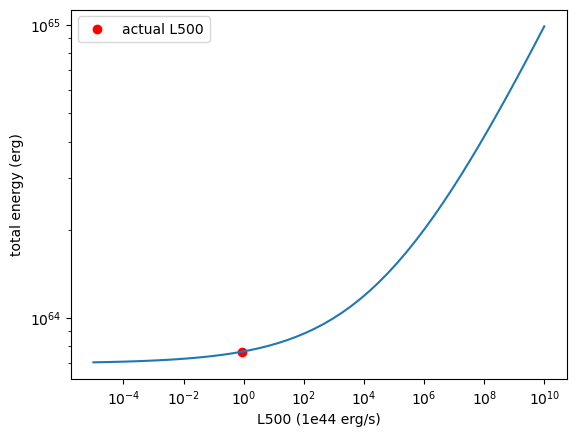

In [154]:
plt.plot(Ls, [E_tot(test_nfw, l).value for l in Ls])
plt.scatter(test_nfw.L500, E_tot(test_nfw), color='red', label="actual L500")
plt.xscale('log')
plt.yscale('log')
plt.xlabel('L500 (1e44 erg/s)')
plt.ylabel('total energy (erg)')
plt.legend()

Text(0, 0.5, 'T500 (GeV)')

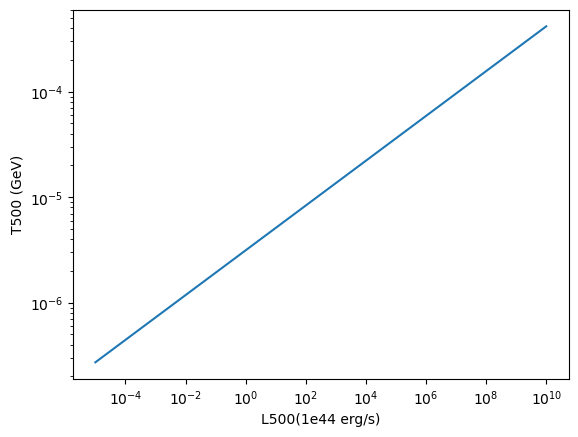

In [157]:
plt.plot(Ls, T500_from_L500(np.log10(Ls)))
plt.xscale('log')
plt.yscale('log')
plt.xlabel('L500(1e44 erg/s)')
plt.ylabel('T500 (GeV)')